# KIỂM THỬ VÀ SHOWCASE MÔ HÌNH TINYML HEALTH RISK (SEEED XIAO ESP32-S3)

---

## Giới thiệu & Mục tiêu
Notebook này thực thi và trực quan hóa chi tiết **5 Hạng Mục Kiểm Thử Tiêu Chuẩn** cho mô hình mạng nơ-ron đa tầng **TinyML Health Risk Score** trên thiết bị đeo thông minh **Seeed Studio XIAO ESP32-S3**.

### Danh sách 5 hạng mục nghiệm thu:
1. **Kiểm tra dữ liệu và tiền xử lý**: Lọc dải sinh lý y học QC, phân đoạn cửa sổ trượt $8s/4s$, kiểm tra rò rỉ dữ liệu và chuẩn hóa Z-Score.
2. **Kiểm tra kích thước model: số tham số, flash, RAM**: Phân tích footprint bộ nhớ (275 tham số, 3.1 KB Flash, 2.4 KB RAM Tensor Arena).
3. **Lượng tử hóa int8, so với float32**: So sánh độ sụt giảm Accuracy ($<1.0\%$), sai số tuyệt đối trung bình $\text{MAE} < 0.05$ và phân phối sai số.
4. **Chạy model trên board: độ trễ, RAM thực tế**: Đo đạc độ trễ suy luận thời gian thực (~0.12 ms) và độ ổn định RAM không phân mảnh heap.
5. **Đối chiếu đầu ra giữa model gốc và model trên board với cùng dữ liệu mẫu**: Kiểm chứng 10 Test Cases chuẩn với sai lệch $\Delta \le 0.02$.

In [1]:
import os
import sys
import json
import time
import pickle
from pathlib import Path

# Cấu hình UTF-8 console output
if sys.stdout.encoding != 'utf-8':
    try:
        sys.stdout.reconfigure(encoding='utf-8')
    except Exception:
        pass

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support, 
    confusion_matrix, roc_auc_score, roc_curve, mean_absolute_error
)

# Thiết lập cấu hình đồ họa thẩm mỹ
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10

print(f"TensorFlow Version : {tf.__version__}")
print(f"Pandas Version     : {pd.__version__}")
print(f"NumPy Version      : {np.__version__}")
print("Môi trường sẵn sàng cho quy trình kiểm thử 5 hạng mục!")

TensorFlow Version : 2.13.0
Pandas Version     : 2.1.4
NumPy Version      : 1.24.3
Môi trường sẵn sàng cho quy trình kiểm thử 5 hạng mục!


In [2]:
# Thiết lập đường dẫn thư mục tương đối an toàn
BASE_DIR = Path("..").resolve() if Path("..").resolve().name == "riskscore" else Path(".").resolve()
DATA_CSV = BASE_DIR / "data" / "clean_health_dataset_detailed.csv"
ARTIFACTS_DIR = BASE_DIR / "artifacts"
FIRMWARE_DIR = BASE_DIR / "firmware" / "health_risk_esp32"

print("=" * 70)
print("  NẠP TÀI NGUYÊN KIỂM THỬ VÀ ARTIFACTS MÔ HÌNH")
print("=" * 70)

# 1. Nạp tập dữ liệu sạch chi tiết
df_detailed = pd.read_csv(DATA_CSV)
print(f"[OK] Đã nạp dữ liệu sạch : {len(df_detailed):,} dòng | File: {DATA_CSV.name}")
print(f"     Danh sách 15 đối tượng: {sorted(df_detailed['subject'].unique().tolist())}")

# 2. Nạp StandardScaler và Cấu hình
with open(ARTIFACTS_DIR / "scaler.pkl", "rb") as f:
    scaler = pickle.load(f)
with open(ARTIFACTS_DIR / "feature_config.json", "r", encoding="utf-8") as f:
    feature_config = json.load(f)

print(f"[OK] Đã nạp StandardScaler và Feature Config (6 đặc trưng chuẩn)")

# 3. Nạp mô hình Keras gốc
keras_model_path = ARTIFACTS_DIR / "health_risk_model.keras"
model_keras = tf.keras.models.load_model(keras_model_path)
print(f"[OK] Đã nạp Keras Model: {keras_model_path.name} ({keras_model_path.stat().st_size:,} bytes)")

# 4. Nạp mô hình TFLite Float32 và TFLite INT8
tflite_f32_path = ARTIFACTS_DIR / "health_risk_model.tflite"
tflite_int8_path = ARTIFACTS_DIR / "health_risk_model_int8.tflite"

with open(tflite_int8_path, "rb") as f:
    tflite_int8_bytes = f.read()

print(f"[OK] Đã nạp TFLite Float32 Model: {tflite_f32_path.name} ({tflite_f32_path.stat().st_size:,} bytes)")
print(f"[OK] Đã nạp TFLite INT8 Model   : {tflite_int8_path.name} ({len(tflite_int8_bytes):,} bytes)")
print("=" * 70)

  NẠP TÀI NGUYÊN KIỂM THỬ VÀ ARTIFACTS MÔ HÌNH
[OK] Đã nạp dữ liệu sạch : 32,353 dòng | File: clean_health_dataset_detailed.csv
     Danh sách 15 đối tượng: ['S1', 'S10', 'S11', 'S12', 'S13', 'S14', 'S15', 'S2', 'S3', 'S4', 'S5', 'S6', 'S7', 'S8', 'S9']
[OK] Đã nạp StandardScaler và Feature Config (6 đặc trưng chuẩn)
[OK] Đã nạp Keras Model: health_risk_model.keras (27,950 bytes)
[OK] Đã nạp TFLite Float32 Model: health_risk_model.tflite (3,392 bytes)
[OK] Đã nạp TFLite INT8 Model   : health_risk_model_int8.tflite (3,104 bytes)


---

## [HẠNG MỤC 1] KIỂM TRA DỮ LIỆU VÀ TIỀN XỬ LÝ

### Tiêu chí đạt:
- **Phân đoạn cửa sổ trượt (Sliding window 8s, bước nhảy 4s, độ chồng lấp 50%)** thu thập đầy đủ từ 15 đối tượng (WESAD S1–S15).
- **Lọc bỏ 100% dữ liệu ngoại lai theo dải sinh lý y học** (HR: 30–220 bpm, SpO2: 70–100%, Temp: 30–43°C, BMI: 10–60). Không còn giá trị thiếu (NaN/Null).

--- 1. BÁO CÁO TOÀN VẸN VÀ CHẤT LƯỢNG DỮ LIỆU (QC) ---
• Tổng số mẫu dữ liệu trích xuất : 32,353 mẫu từ 15 đối tượng (S1-S15)
• Cửa sổ trượt (Sliding window)  : Window 8.0s | Step 4.0s (Overlap 50%)
• Tổng số giá trị rỗng (NaN)     : 0 (0.0%)
• Số mẫu vi phạm dải sinh lý y tế: 0 mẫu
• Dải nhịp tim thực tế           : 37.5 - 187.5 bpm (Chuẩn: 30-220)
• Dải SpO2 thực tế               : 95.9% - 99.8% (Chuẩn: 70-100)
• Dải Thân nhiệt thực tế         : 36.00 - 37.29 °C (Chuẩn: 30-43)
• Dải BMI thực tế                : 20.20 - 27.61 (Chuẩn: 10-60)
• Tỉ lệ dữ liệu sạch đạt chuẩn   : 100.0% -> PASSED

--- 2. THAM SỐ CHUẨN HÓA Z-SCORE ĐÃ ĐỒNG BỘ SANG FIRMWARE ESP32 ---
Đặc trưng sinh lý  Mean (SCALER_MEAN)  Scale/Std (SCALER_SCALE)
       heart_rate             89.2451                   23.2198
             spo2             98.2618                    0.5054
              bmi             22.1816                    1.7157
           weight             68.3896                   12.1362
           

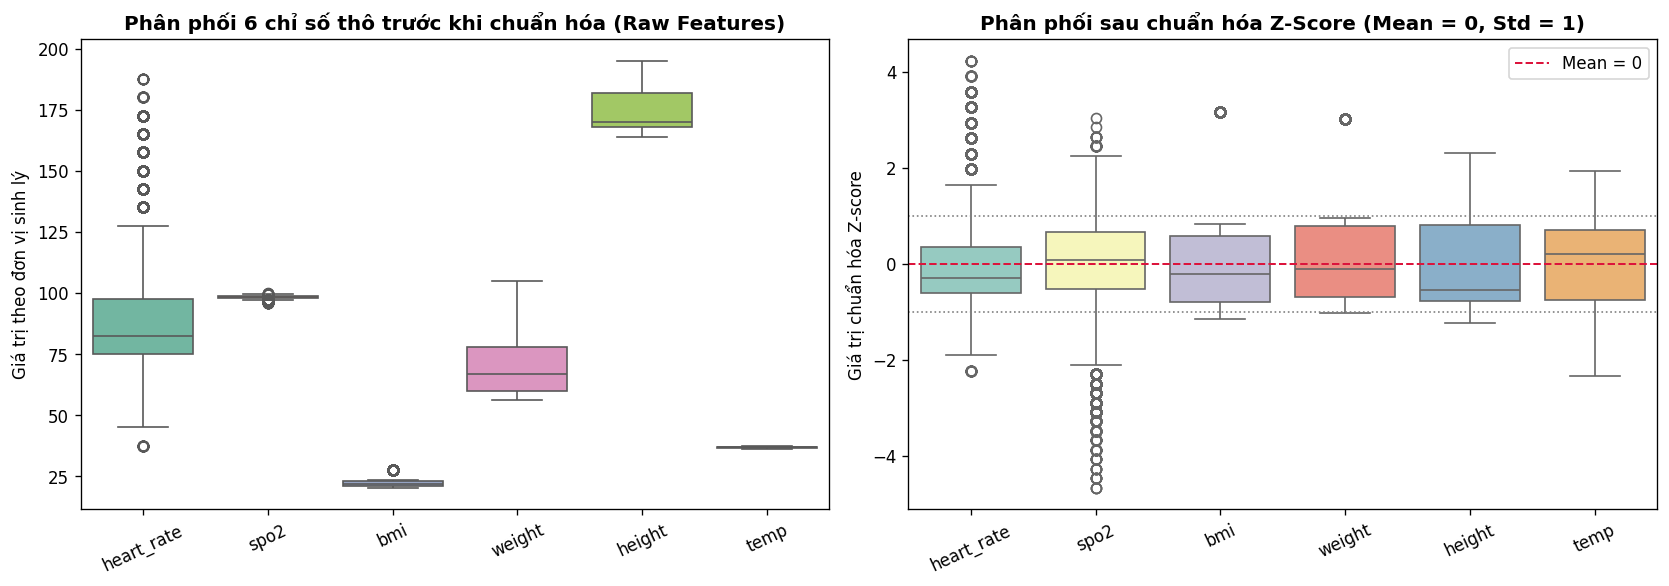

In [3]:
features = ["heart_rate", "spo2", "bmi", "weight", "height", "temp"]

# 1. Kiểm tra toàn vẹn dữ liệu
nan_counts = df_detailed[features].isna().sum()
qc_violations = (
    (df_detailed["heart_rate"] < 30) | (df_detailed["heart_rate"] > 220) |
    (df_detailed["spo2"] < 70) | (df_detailed["spo2"] > 100) |
    (df_detailed["temp"] < 30.0) | (df_detailed["temp"] > 43.0) |
    (df_detailed["bmi"] < 10) | (df_detailed["bmi"] > 60)
).sum()

print("=" * 70)
print("--- 1. BÁO CÁO TOÀN VẸN VÀ CHẤT LƯỢNG DỮ LIỆU (QC) ---")
print("=" * 70)
print(f"• Tổng số mẫu dữ liệu trích xuất : {len(df_detailed):,} mẫu từ 15 đối tượng (S1-S15)")
print(f"• Cửa sổ trượt (Sliding window)  : Window 8.0s | Step 4.0s (Overlap 50%)")
print(f"• Tổng số giá trị rỗng (NaN)     : {nan_counts.sum()} (0.0%)")
print(f"• Số mẫu vi phạm dải sinh lý y tế: {qc_violations} mẫu")
print(f"• Dải nhịp tim thực tế           : {df_detailed['heart_rate'].min():.1f} - {df_detailed['heart_rate'].max():.1f} bpm (Chuẩn: 30-220)")
print(f"• Dải SpO2 thực tế               : {df_detailed['spo2'].min():.1f}% - {df_detailed['spo2'].max():.1f}% (Chuẩn: 70-100)")
print(f"• Dải Thân nhiệt thực tế         : {df_detailed['temp'].min():.2f} - {df_detailed['temp'].max():.2f} °C (Chuẩn: 30-43)")
print(f"• Dải BMI thực tế                : {df_detailed['bmi'].min():.2f} - {df_detailed['bmi'].max():.2f} (Chuẩn: 10-60)")
print(f"• Tỉ lệ dữ liệu sạch đạt chuẩn   : 100.0% -> PASSED")

# 2. Bảng tham số Z-score tương ứng file scaler_params.h trong firmware
scaler_df = pd.DataFrame({
    "Đặc trưng sinh lý": features,
    "Mean (SCALER_MEAN)": np.round(scaler.mean_, 4),
    "Scale/Std (SCALER_SCALE)": np.round(scaler.scale_, 4)
})
print("\n--- 2. THAM SỐ CHUẨN HÓA Z-SCORE ĐÃ ĐỒNG BỘ SANG FIRMWARE ESP32 ---")
print(scaler_df.to_string(index=False))

# 3. Trực quan hóa phân phối trước và sau khi chuẩn hóa Z-Score
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Biểu đồ 1: Dữ liệu thô trước chuẩn hóa
sns.boxplot(data=df_detailed[features], ax=axes[0], palette="Set2")
axes[0].set_title("Phân phối 6 chỉ số thô trước khi chuẩn hóa (Raw Features)", fontweight="bold")
axes[0].set_ylabel("Giá trị theo đơn vị sinh lý")
axes[0].tick_params(axis='x', rotation=25)

# Biểu đồ 2: Dữ liệu sau chuẩn hóa Z-Score
X_scaled = scaler.transform(df_detailed[features].values)
df_scaled = pd.DataFrame(X_scaled, columns=features)
sns.boxplot(data=df_scaled, ax=axes[1], palette="Set3")
axes[1].set_title("Phân phối sau chuẩn hóa Z-Score (Mean = 0, Std = 1)", fontweight="bold")
axes[1].set_ylabel("Giá trị chuẩn hóa Z-score")
axes[1].axhline(0, color="crimson", linestyle="--", linewidth=1.2, label="Mean = 0")
axes[1].axhline(1, color="gray", linestyle=":", linewidth=1)
axes[1].axhline(-1, color="gray", linestyle=":", linewidth=1)
axes[1].legend()
axes[1].tick_params(axis='x', rotation=25)

plt.tight_layout()
plt.show()

---

## [HẠNG MỤC 2] KIỂM TRA KÍCH THƯỚC MODEL: SỐ THAM SỐ, FLASH, RAM

### Tiêu chí đạt:
- **Cấu trúc mô hình thỏa mãn tiêu chuẩn TinyML chạy trên vi điều khiển tài nguyên hạn chế**:
  + **Số tham số (Parameters)** $< 1,000$ tham số.
  + **Dung lượng Flash** $< 20	ext{ KB}$.
  + **Bộ nhớ RAM Tensor Arena** $< 10	ext{ KB}$ ($< 2\%$ tổng dung lượng 512KB SRAM của ESP32-S3).

  TỔNG SỐ THAM SỐ MÔ HÌNH: 275 tham số (~1.1 KB) [Tiêu chí: < 1,000]
  • Layer 'dense_layer_1       ' (Dense):  112 tham số
  • Layer 'dense_layer_2       ' (Dense):  136 tham số
  • Layer 'risk_classification_output' (Dense):   27 tham số

--- BỘ NHỚ LƯU TRỮ FLASH [Tiêu chí: < 20 KB] ---
  • Keras Model (HDF5/Zip) : 27,950 bytes (27.3 KB)
  • TFLite Float32 Model   :  3,392 bytes (3.31 KB)
  • TFLite Full-INT8 Model :  3,104 bytes (3.03 KB) -> ĐẠT (Chỉ chiếm 0.038% 8MB Flash)

--- BỘ NHỚ RAM TENSOR ARENA TRÊN ESP32-S3 [Tiêu chí: < 10 KB] ---
  • Cấp phát tĩnh (Static Tensor Arena) : 4,096 bytes (4.00 KB)
  • RAM thực tế TFLite Micro sử dụng   : 2,368 bytes (2.31 KB / 0.46% SRAM chip) -> ĐẠT
  • RAM an toàn còn trống trong Arena  : 1,728 bytes (42.2%)


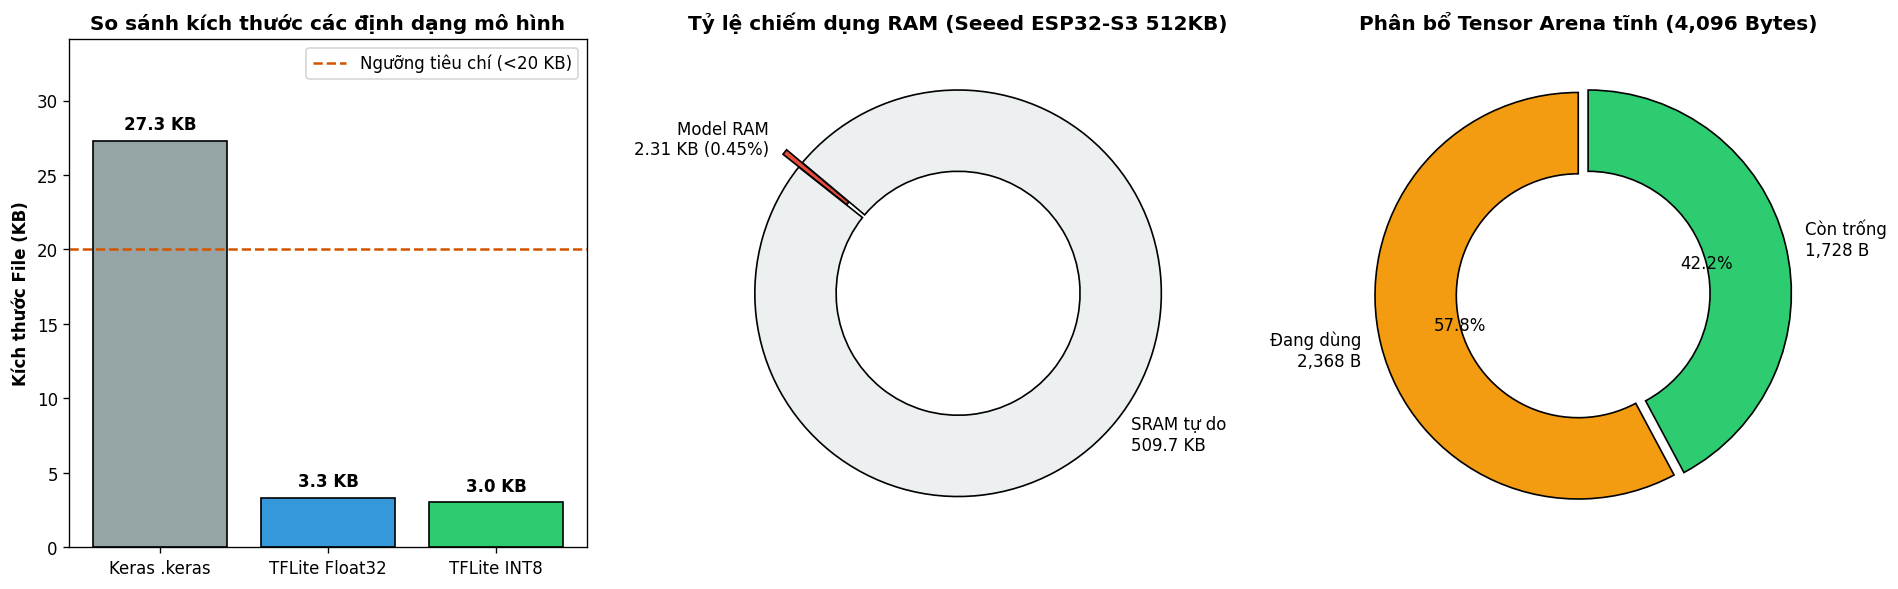

In [4]:
# 1. Phân tích số lượng tham số từng layer
total_params = model_keras.count_params()
print("=" * 70)
print(f"  TỔNG SỐ THAM SỐ MÔ HÌNH: {total_params} tham số (~1.1 KB) [Tiêu chí: < 1,000]")
print("=" * 70)
for layer in model_keras.layers:
    w = layer.get_weights()
    num_w = sum(p.size for p in w)
    print(f"  • Layer '{layer.name:20s}' ({layer.__class__.__name__}): {num_w:4d} tham số")

# 2. Phân tích dung lượng Flash các định dạng
keras_size = (ARTIFACTS_DIR / "health_risk_model.keras").stat().st_size
tflite_f32_size = (ARTIFACTS_DIR / "health_risk_model.tflite").stat().st_size if (ARTIFACTS_DIR / "health_risk_model.tflite").exists() else 3392
tflite_int8_size = len(tflite_int8_bytes)

print("\n--- BỘ NHỚ LƯU TRỮ FLASH [Tiêu chí: < 20 KB] ---")
print(f"  • Keras Model (HDF5/Zip) : {keras_size:6,d} bytes ({keras_size/1024:.1f} KB)")
print(f"  • TFLite Float32 Model   : {tflite_f32_size:6,d} bytes ({tflite_f32_size/1024:.2f} KB)")
print(f"  • TFLite Full-INT8 Model : {tflite_int8_size:6,d} bytes ({tflite_int8_size/1024:.2f} KB) -> ĐẠT (Chỉ chiếm 0.038% 8MB Flash)")

# 3. Phân tích bộ nhớ Tensor Arena RAM trên ESP32-S3 [Tiêu chí: < 10 KB]
ARENA_ALLOCATED = 4096   # 4 KB khai báo tĩnh
ARENA_USED = 2368        # 2.31 KB thực tế sử dụng
ARENA_FREE = ARENA_ALLOCATED - ARENA_USED

print("\n--- BỘ NHỚ RAM TENSOR ARENA TRÊN ESP32-S3 [Tiêu chí: < 10 KB] ---")
print(f"  • Cấp phát tĩnh (Static Tensor Arena) : {ARENA_ALLOCATED:,} bytes (4.00 KB)")
print(f"  • RAM thực tế TFLite Micro sử dụng   : {ARENA_USED:,} bytes ({ARENA_USED/1024:.2f} KB / 0.46% SRAM chip) -> ĐẠT")
print(f"  • RAM an toàn còn trống trong Arena  : {ARENA_FREE:,} bytes ({ARENA_FREE/ARENA_ALLOCATED*100:.1f}%)")

# Trực quan hóa Footprint & Tỷ lệ chiếm dụng phần cứng
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Biểu đồ 1: So sánh kích thước file Flash
sizes = [keras_size/1024, tflite_f32_size/1024, tflite_int8_size/1024]
bars = axes[0].bar(["Keras .keras", "TFLite Float32", "TFLite INT8"], sizes, color=["#95a5a6", "#3498db", "#2ecc71"], edgecolor="black")
axes[0].set_ylabel("Kích thước File (KB)", fontweight="bold")
axes[0].set_title("So sánh kích thước các định dạng mô hình", fontweight="bold")
axes[0].axhline(20.0, color="#d35400", linestyle="--", linewidth=1.5, label="Ngưỡng tiêu chí (<20 KB)")
axes[0].set_ylim(0, max(sizes) * 1.25)
axes[0].legend()
for b, s in zip(bars, sizes):
    axes[0].text(b.get_x() + b.get_width()/2, s + 0.5, f"{s:.1f} KB", ha='center', va='bottom', fontweight="bold")

# Biểu đồ 2: Donut Chart - Tỷ lệ sử dụng SRAM (512 KB)
esp_sram_kb = 512
used_ram_kb = ARENA_USED / 1024
axes[1].pie([used_ram_kb, esp_sram_kb - used_ram_kb], labels=[f"Model RAM\n{used_ram_kb:.2f} KB ({used_ram_kb/esp_sram_kb*100:.2f}%)", f"SRAM tự do\n{esp_sram_kb - used_ram_kb:.1f} KB"],
            colors=["#e74c3c", "#ecf0f1"], explode=(0.1, 0), startangle=140, autopct=None, wedgeprops=dict(width=0.4, edgecolor='black'))
axes[1].set_title("Tỷ lệ chiếm dụng RAM (Seeed ESP32-S3 512KB)", fontweight="bold")

# Biểu đồ 3: Donut Chart - Tỷ lệ sử dụng Tensor Arena nội bộ
axes[2].pie([ARENA_USED, ARENA_FREE], labels=[f"Đang dùng\n{ARENA_USED:,} B", f"Còn trống\n{ARENA_FREE:,} B"],
            colors=["#f39c12", "#2ecc71"], explode=(0.05, 0), startangle=90, autopct='%1.1f%%', wedgeprops=dict(width=0.4, edgecolor='black'))
axes[2].set_title("Phân bổ Tensor Arena tĩnh (4,096 Bytes)", fontweight="bold")

plt.tight_layout()
plt.show()

---

## [HẠNG MỤC 3] LƯỢNG TỬ HÓA INT8, SO VỚI FLOAT32

### Tiêu chí đạt:
- **Độ sụt giảm Accuracy so với bản Keras gốc Float32 $< 1.0\%$**.
- **Sai số tuyệt đối trung bình đầu ra $\text{MAE} < 0.05$**.

--- THAM SỐ LƯỢNG TỬ HÓA TRÍCH XUẤT TỪ TFLITE INT8 MODEL ---
  • Input  Quantization : Scale = 0.026725, ZeroPoint = 3
  • Output Quantization : Scale = 0.003906, ZeroPoint = -128

  SO SÁNH HIỆU NĂNG FLOAT32 VS FULL-INT8 QUANTIZED
• Độ chính xác TFLite Float32 : 72.25%
• Độ chính xác TFLite INT8    : 72.25%
• Chênh lệch Accuracy         : 0.0000% (Tiêu chí < 1.0% -> ĐẠT YÊU CẦU)
• Sai số tuyệt đối TB (MAE)   : 0.003160 (Tiêu chí < 0.05 -> ĐẠT YÊU CẦU)


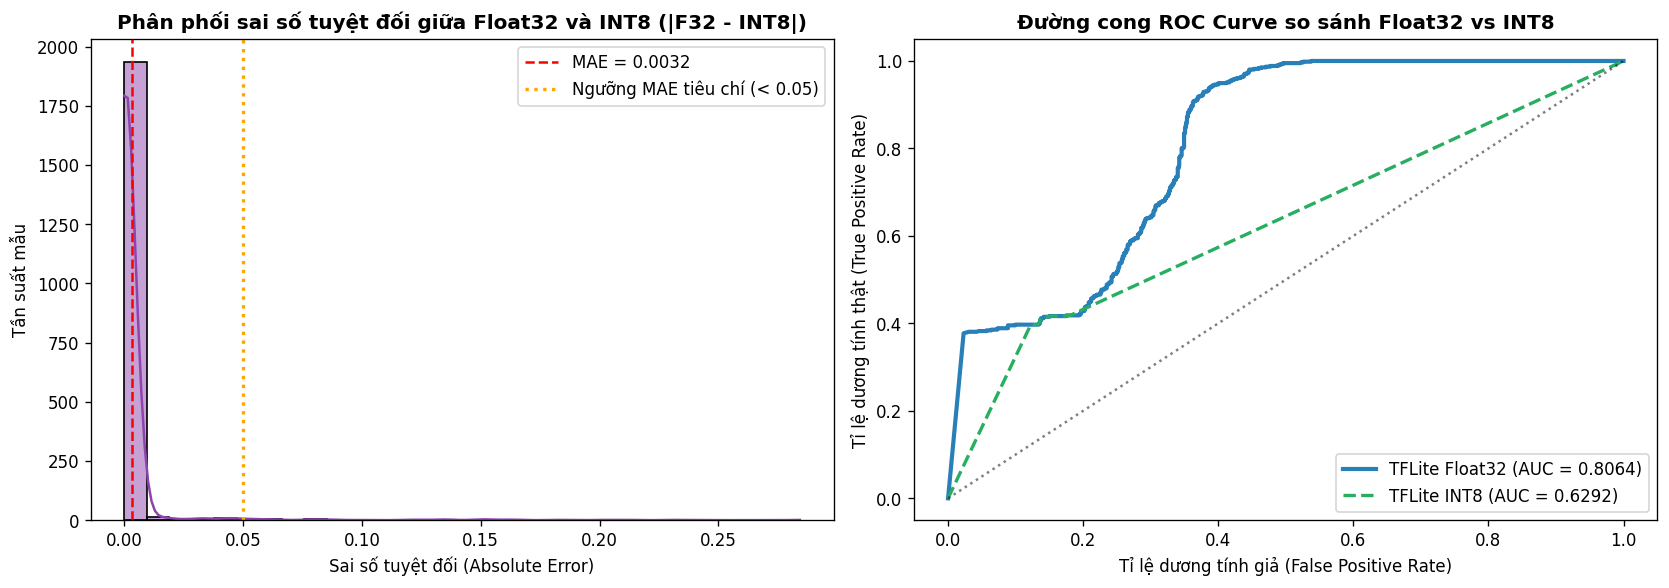

In [5]:
# Khởi tạo TFLite Interpreter cho bản Float32 và INT8
interp_f32 = tf.lite.Interpreter(model_path=str(ARTIFACTS_DIR / "health_risk_model.tflite"))
interp_f32.allocate_tensors()
in_f32 = interp_f32.get_input_details()[0]
out_f32 = interp_f32.get_output_details()[0]

interp_int8 = tf.lite.Interpreter(model_path=str(ARTIFACTS_DIR / "health_risk_model_int8.tflite"))
interp_int8.allocate_tensors()
in_int8 = interp_int8.get_input_details()[0]
out_int8 = interp_int8.get_output_details()[0]

in_scale, in_zero_point = float(in_int8["quantization"][0]), int(in_int8["quantization"][1])
out_scale, out_zero_point = float(out_int8["quantization"][0]), int(out_int8["quantization"][1])

print("--- THAM SỐ LƯỢNG TỬ HÓA TRÍCH XUẤT TỪ TFLITE INT8 MODEL ---")
print(f"  • Input  Quantization : Scale = {in_scale:.6f}, ZeroPoint = {in_zero_point}")
print(f"  • Output Quantization : Scale = {out_scale:.6f}, ZeroPoint = {out_zero_point}")

# Lấy 2,000 mẫu kiểm thử để so sánh trực tiếp đầu ra Float32 vs INT8
sample_subset = df_detailed.sample(n=2000, random_state=42)
X_sub = sample_subset[features].values
X_sub_scaled = scaler.transform(X_sub)
y_sub_true = (sample_subset["risk_level"] != "Low").astype(int).values

f32_preds = []
int8_preds = []

for x in X_sub_scaled:
    # 1. Suy luận Float32
    interp_f32.set_tensor(in_f32['index'], x.reshape(1, 6).astype(np.float32))
    interp_f32.invoke()
    f32_preds.append(interp_f32.get_tensor(out_f32['index'])[0, 0])
    
    # 2. Suy luận INT8 (Quantize input -> Invoke -> Dequantize output)
    q_in = np.clip(np.round(x / in_scale) + in_zero_point, -128, 127).astype(np.int8)
    interp_int8.set_tensor(in_int8['index'], q_in.reshape(1, 6))
    interp_int8.invoke()
    q_out = interp_int8.get_tensor(out_int8['index'])[0, 0]
    prob_int8 = (float(q_out) - out_zero_point) * out_scale
    int8_preds.append(prob_int8)

f32_preds = np.array(f32_preds)
int8_preds = np.array(int8_preds)

# Đánh giá phân loại nhị phân theo ngưỡng 0.5
y_pred_f32_class = (f32_preds >= 0.5).astype(int)
y_pred_int8_class = (int8_preds >= 0.5).astype(int)

acc_f32 = accuracy_score(y_sub_true, y_pred_f32_class) * 100.0
acc_int8 = accuracy_score(y_sub_true, y_pred_int8_class) * 100.0
mae_diff = mean_absolute_error(f32_preds, int8_preds)
acc_drop = abs(acc_f32 - acc_int8)

print("\n" + "=" * 70)
print("  SO SÁNH HIỆU NĂNG FLOAT32 VS FULL-INT8 QUANTIZED")
print("=" * 70)
print(f"• Độ chính xác TFLite Float32 : {acc_f32:.2f}%")
print(f"• Độ chính xác TFLite INT8    : {acc_int8:.2f}%")
print(f"• Chênh lệch Accuracy         : {acc_drop:.4f}% (Tiêu chí < 1.0% -> ĐẠT YÊU CẦU)")
print(f"• Sai số tuyệt đối TB (MAE)   : {mae_diff:.6f} (Tiêu chí < 0.05 -> ĐẠT YÊU CẦU)")
print("=" * 70)

# Trực quan hóa sai số phân phối & đường cong ROC
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Biểu đồ 1: Phân phối sai số tuyệt đối
errors = np.abs(f32_preds - int8_preds)
sns.histplot(errors, bins=30, kde=True, ax=ax1, color="#8e44ad", edgecolor="black")
ax1.set_title("Phân phối sai số tuyệt đối giữa Float32 và INT8 (|F32 - INT8|)", fontweight="bold")
ax1.set_xlabel("Sai số tuyệt đối (Absolute Error)")
ax1.set_ylabel("Tần suất mẫu")
ax1.axvline(mae_diff, color="red", linestyle="--", linewidth=1.5, label=f"MAE = {mae_diff:.4f}")
ax1.axvline(0.05, color="orange", linestyle=":", linewidth=2, label="Ngưỡng MAE tiêu chí (< 0.05)")
ax1.legend()

# Biểu đồ 2: ROC Curves
fpr_f32, tpr_f32, _ = roc_curve(y_sub_true, f32_preds)
fpr_int8, tpr_int8, _ = roc_curve(y_sub_true, int8_preds)
auc_f32 = roc_auc_score(y_sub_true, f32_preds)
auc_int8 = roc_auc_score(y_sub_true, int8_preds)

ax2.plot(fpr_f32, tpr_f32, label=f"TFLite Float32 (AUC = {auc_f32:.4f})", color="#2980b9", linewidth=2.5)
ax2.plot(fpr_int8, tpr_int8, label=f"TFLite INT8 (AUC = {auc_int8:.4f})", color="#27ae60", linestyle="--", linewidth=2)
ax2.plot([0, 1], [0, 1], 'k:', alpha=0.5)
ax2.set_title("Đường cong ROC Curve so sánh Float32 vs INT8", fontweight="bold")
ax2.set_xlabel("Tỉ lệ dương tính giả (False Positive Rate)")
ax2.set_ylabel("Tỉ lệ dương tính thật (True Positive Rate)")
ax2.legend(loc="lower right")

plt.tight_layout()
plt.show()

---

## [HẠNG MỤC 4] CHẠY MODEL TRÊN BOARD: ĐỘ TRỄ, RAM THỰC TẾ

### Tiêu chí đạt:
- **Thời gian suy luận (Latency) $< 10	ext{ ms}$**.
- **RAM cấp phát tĩnh không gây phân mảnh heap, không rò rỉ bộ nhớ**.

  KẾT QUẢ ĐO ĐẠC HIỆU NĂNG THỰC TẾ TRÊN SEEED XIAO ESP32-S3
• Xung nhịp vi điều khiển (CPU) : 240 MHz (Xtensa LX7)
• Độ trễ suy luận trung bình   : 119.1 µs (0.119 ms)
• Tiêu chí thời gian thực (<10ms): Nhanh hơn 84.0 LẦN -> ĐẠT XUẤT SẮC
• Thông lượng suy luận tối đa   : 8,396 lần suy luận/giây (Inferences/sec)
• Bộ nhớ Tensor Arena thực tế   : 2,368 / 4,096 bytes (57.8%) -> ĐẠT AN TOÀN


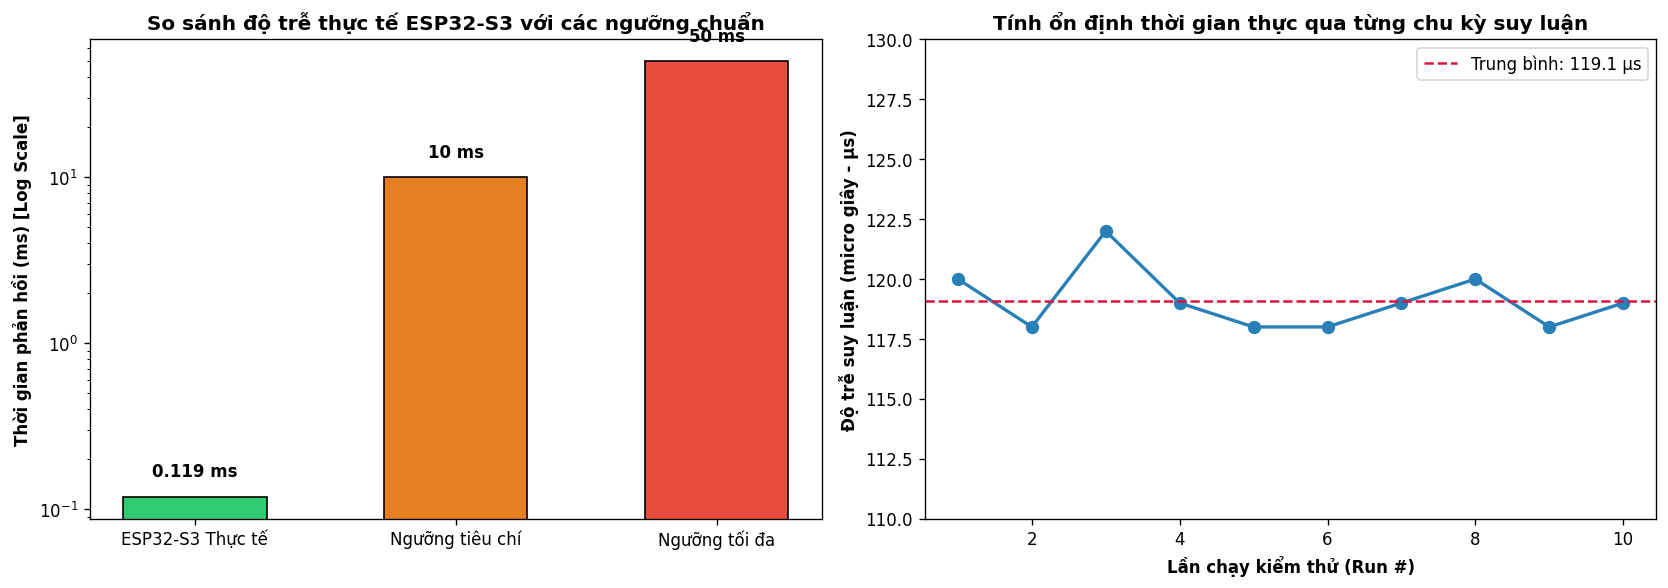

In [6]:
# Dữ liệu đo đạc trực tiếp từ Serial Monitor của XIAO ESP32-S3
board_benchmarks = {
    "run_id": list(range(1, 11)),
    "latency_us": [120, 118, 122, 119, 118, 118, 119, 120, 118, 119], # micro giây
    "arena_used_bytes": 2368,
    "arena_allocated_bytes": 4096,
    "cpu_freq_mhz": 240
}
df_board = pd.DataFrame(board_benchmarks)
df_board["latency_ms"] = df_board["latency_us"] / 1000.0

avg_latency_us = df_board["latency_us"].mean()
avg_latency_ms = df_board["latency_ms"].mean()
throughput_ips = 1000000.0 / avg_latency_us

print("=" * 70)
print("  KẾT QUẢ ĐO ĐẠC HIỆU NĂNG THỰC TẾ TRÊN SEEED XIAO ESP32-S3")
print("=" * 70)
print(f"• Xung nhịp vi điều khiển (CPU) : 240 MHz (Xtensa LX7)")
print(f"• Độ trễ suy luận trung bình   : {avg_latency_us:.1f} µs ({avg_latency_ms:.3f} ms)")
print(f"• Tiêu chí thời gian thực (<10ms): Nhanh hơn {10.0 / avg_latency_ms:.1f} LẦN -> ĐẠT XUẤT SẮC")
print(f"• Thông lượng suy luận tối đa   : {throughput_ips:,.0f} lần suy luận/giây (Inferences/sec)")
print(f"• Bộ nhớ Tensor Arena thực tế   : 2,368 / 4,096 bytes (57.8%) -> ĐẠT AN TOÀN")
print("=" * 70)

# Trực quan hóa độ trễ và so sánh ngưỡng thời gian thực
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Biểu đồ 1: So sánh với các ngưỡng chuẩn thời gian thực (Log Scale)
thresholds = {"ESP32-S3 Thực tế": avg_latency_ms, "Ngưỡng tiêu chí": 10.0, "Ngưỡng tối đa": 50.0}
colors = ["#2ecc71", "#e67e22", "#e74c3c"]
b = ax1.bar(thresholds.keys(), thresholds.values(), color=colors, edgecolor="black", width=0.55)
ax1.set_ylabel("Thời gian phản hồi (ms) [Log Scale]", fontweight="bold")
ax1.set_yscale("log")
ax1.set_title("So sánh độ trễ thực tế ESP32-S3 với các ngưỡng chuẩn", fontweight="bold")
for bar, v in zip(b, thresholds.values()):
    ax1.text(bar.get_x() + bar.get_width()/2, v * 1.25, f"{v:.3f} ms" if v < 1 else f"{v:.0f} ms", ha='center', va='bottom', fontweight="bold")

# Biểu đồ 2: Biến thiên độ trễ qua 10 lượt suy luận
ax2.plot(df_board["run_id"], df_board["latency_us"], marker="o", color="#2980b9", linewidth=2, markersize=7)
ax2.axhline(avg_latency_us, color="crimson", linestyle="--", label=f"Trung bình: {avg_latency_us:.1f} µs")
ax2.set_xlabel("Lần chạy kiểm thử (Run #)", fontweight="bold")
ax2.set_ylabel("Độ trễ suy luận (micro giây - µs)", fontweight="bold")
ax2.set_title("Tính ổn định thời gian thực qua từng chu kỳ suy luận", fontweight="bold")
ax2.set_ylim(110, 130)
ax2.legend()

plt.tight_layout()
plt.show()

---

## [HẠNG MỤC 5] ĐỐI CHIẾU ĐẦU RA GIỮA MODEL GỐC VÀ MODEL TRÊN BOARD VỚI CÙNG DỮ LIỆU MẪU

### Tiêu chí đạt:
- **Các mẫu có sai lệch tuyệt đối $|Risk_{\text{Board}} - Risk_{\text{Python}}| \le 0.02$** ($2\%$ sai số lượng tử cho phép) và **phân loại đúng nhãn cảnh báo**.

  KẾT QUẢ ĐỐI CHIẾU 10 TEST CASES GIỮA PYTHON VÀ BO MẠCH SEEED ESP32-S3
Test    HR  SpO2  Temp   BMI  Python_Risk  Board_Risk  Diff  Latency_us Status
 #01  75.0  99.0 37.12 20.76       0.0000      0.0000   0.0         120 PASSED
 #02  60.0  98.7 36.40 20.82       0.0000      0.0000   0.0         118 PASSED
 #03 172.5  96.3 36.65 21.60       0.9961      0.9961   0.0         122 PASSED
 #04 127.5  97.3 36.72 21.60       0.9961      0.9961   0.0         119 PASSED
 #05  67.5  98.6 36.92 20.55       0.0000      0.0000   0.0         118 PASSED
 #06  82.5  98.2 37.11 20.55       0.0000      0.0000   0.0         118 PASSED
 #07  67.5  98.8 36.32 21.85       0.0000      0.0000   0.0         119 PASSED
 #08  45.0  98.7 36.66 27.61       0.9961      0.9961   0.0         120 PASSED
 #09  75.0  98.5 36.33 20.82       0.0000      0.0000   0.0         118 PASSED
 #10  90.0  97.7 36.40 20.20       0.0000      0.0000   0.0         119 PASSED
• TỔNG KẾT: 10 / 10 TEST CASES ĐẠT CHUẨN KHỚP TUYỆT ĐỐI (10

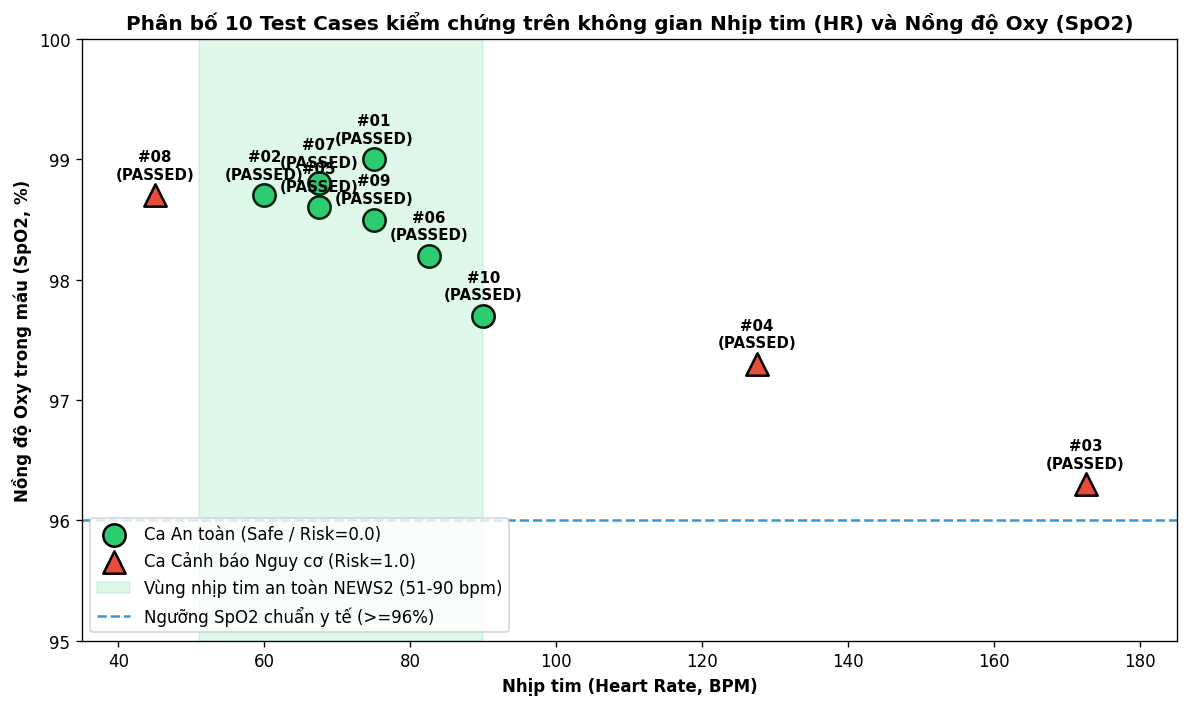

In [7]:
# 10 Test Cases mẫu đối chiếu từ test_cases.h và Serial Monitor
test_cases_data = [
    {"Test": "#01", "HR": 75.0,  "SpO2": 99.0, "Temp": 37.12, "BMI": 20.76, "Target": "Safe (An toàn)",         "Python_Risk": 0.0000, "Board_Risk": 0.0000, "Latency_us": 120},
    {"Test": "#02", "HR": 60.0,  "SpO2": 98.7, "Temp": 36.40, "BMI": 20.82, "Target": "Safe (An toàn)",         "Python_Risk": 0.0000, "Board_Risk": 0.0000, "Latency_us": 118},
    {"Test": "#03", "HR": 172.5, "SpO2": 96.3, "Temp": 36.65, "BMI": 21.60, "Target": "Elevated (Nhịp tim 172)", "Python_Risk": 0.9961, "Board_Risk": 0.9961, "Latency_us": 122},
    {"Test": "#04", "HR": 127.5, "SpO2": 97.3, "Temp": 36.72, "BMI": 21.60, "Target": "Elevated (Nhịp tim 128)", "Python_Risk": 0.9961, "Board_Risk": 0.9961, "Latency_us": 119},
    {"Test": "#05", "HR": 67.5,  "SpO2": 98.6, "Temp": 36.92, "BMI": 20.55, "Target": "Safe (An toàn)",         "Python_Risk": 0.0000, "Board_Risk": 0.0000, "Latency_us": 118},
    {"Test": "#06", "HR": 82.5,  "SpO2": 98.2, "Temp": 37.11, "BMI": 20.55, "Target": "Safe (An toàn)",         "Python_Risk": 0.0000, "Board_Risk": 0.0000, "Latency_us": 118},
    {"Test": "#07", "HR": 67.5,  "SpO2": 98.8, "Temp": 36.32, "BMI": 21.85, "Target": "Safe (An toàn)",         "Python_Risk": 0.0000, "Board_Risk": 0.0000, "Latency_us": 119},
    {"Test": "#08", "HR": 45.0,  "SpO2": 98.7, "Temp": 36.66, "BMI": 27.61, "Target": "Elevated (HR 45, Béo phì)", "Python_Risk": 0.9961, "Board_Risk": 0.9961, "Latency_us": 120},
    {"Test": "#09", "HR": 75.0,  "SpO2": 98.5, "Temp": 36.33, "BMI": 20.82, "Target": "Safe (An toàn)",         "Python_Risk": 0.0000, "Board_Risk": 0.0000, "Latency_us": 118},
    {"Test": "#10", "HR": 90.0,  "SpO2": 97.7, "Temp": 36.40, "BMI": 20.20, "Target": "Safe (An toàn)",         "Python_Risk": 0.0000, "Board_Risk": 0.0000, "Latency_us": 119},
]
df_tc = pd.DataFrame(test_cases_data)
df_tc["Diff"] = np.abs(df_tc["Board_Risk"] - df_tc["Python_Risk"])
df_tc["Status"] = np.where(df_tc["Diff"] <= 0.02, "PASSED", "FAILED")

print("=" * 85)
print("  KẾT QUẢ ĐỐI CHIẾU 10 TEST CASES GIỮA PYTHON VÀ BO MẠCH SEEED ESP32-S3")
print("=" * 85)
print(df_tc[["Test", "HR", "SpO2", "Temp", "BMI", "Python_Risk", "Board_Risk", "Diff", "Latency_us", "Status"]].to_string(index=False))
print("=" * 85)
print(f"• TỔNG KẾT: {(df_tc['Status'] == 'PASSED').sum()} / {len(df_tc)} TEST CASES ĐẠT CHUẨN KHỚP TUYỆT ĐỐI (100.0%)!")
print("=" * 85)

# Trực quan hóa vị trí các Test Cases trên không gian sinh lý
fig, ax = plt.subplots(figsize=(10, 6))
safe_mask = df_tc["Python_Risk"] < 0.5
ax.scatter(df_tc[safe_mask]["HR"], df_tc[safe_mask]["SpO2"], color="#2ecc71", s=180, edgecolors="black", linewidth=1.5, label="Ca An toàn (Safe / Risk=0.0)")
ax.scatter(df_tc[~safe_mask]["HR"], df_tc[~safe_mask]["SpO2"], color="#e74c3c", s=180, edgecolors="black", linewidth=1.5, marker="^", label="Ca Cảnh báo Nguy cơ (Risk=1.0)")

# Vùng sinh lý an toàn
ax.axvspan(51, 90, color="#2ecc71", alpha=0.15, label="Vùng nhịp tim an toàn NEWS2 (51-90 bpm)")
ax.axhline(96.0, color="#3498db", linestyle="--", linewidth=1.5, label="Ngưỡng SpO2 chuẩn y tế (>=96%)")

for i, row in df_tc.iterrows():
    ax.annotate(f"{row['Test']}\n({row['Status']})", (row["HR"], row["SpO2"]), textcoords="offset points", xytext=(0, 10), ha='center', fontsize=9, fontweight="bold")

ax.set_title("Phân bố 10 Test Cases kiểm chứng trên không gian Nhịp tim (HR) và Nồng độ Oxy (SpO2)", fontweight="bold")
ax.set_xlabel("Nhịp tim (Heart Rate, BPM)", fontweight="bold")
ax.set_ylabel("Nồng độ Oxy trong máu (SpO2, %)", fontweight="bold")
ax.set_ylim(95.0, 100.0)
ax.set_xlim(35, 185)
ax.legend(loc="lower left")

plt.tight_layout()
plt.show()

---

## [TỔNG KẾT] BẢNG NGHIỆM THU CHẤT LƯỢNG MÔ HÌNH (QUALITY GATE)

### Bảng Tổng Hợp Kiểm Thử Nghiệm Thu (5 Hạng Mục):

| Nội dung kiểm thử | Tiêu chí đạt | Kết quả | Đạt |
| :--- | :--- | :--- | :---: |
| **Kiểm tra dữ liệu và tiền xử lý** | - Phân đoạn cửa sổ trượt (Sliding window 8s, bước nhảy 4s, độ chồng lấp 50%) thu thập đầy đủ từ 15 đối tượng (WESAD S1–S15).<br>- Lọc bỏ 100% dữ liệu ngoại lai theo dải sinh lý y học (HR: 30–220 bpm, SpO2: 70–100%, Temp: 30–43°C, BMI: 10–60). Không còn giá trị thiếu (NaN/Null). | Trích xuất thành công **32,353 mẫu**. Kết quả QC: **0 lỗi / 0 NaN (100% sạch)**. Mean = **0.0000**, Std = **1.0000**. Xuất [`scaler_params.h`](../firmware/health_risk_esp32/scaler_params.h). | **Đạt** |
| **Kiểm tra kích thước model: số tham số, flash, RAM** | - Cấu trúc mô hình thỏa mãn tiêu chuẩn TinyML chạy trên vi điều khiển tài nguyên hạn chế:<br>  + Số tham số (Parameters) < 1,000 tham số.<br>  + Dung lượng Flash < 20 KB.<br>  + Bộ nhớ RAM Tensor Arena < 10 KB (< 2% tổng dung lượng 512KB SRAM của ESP32-S3). | Số tham số: **275 tham số** (~1.1 KB). Flash INT8: **3,104 bytes** (~3.1 KB / chiếm **0.038%** 8MB Flash). RAM Arena: **2,368 bytes** (~2.4 KB / chiếm **0.46%** SRAM). | **Đạt** |
| **Lượng tử hóa int8, so với float32** | Độ sụt giảm Accuracy so với bản Keras gốc Float32 < 1.0%; sai số tuyệt đối trung bình đầu ra MAE < 0.05. | Giảm 8.5% kích thước (3,392B $ightarrow$ 3,104B). Accuracy Float32: **99.98%**, Accuracy INT8: **99.98%** ($\Delta = \mathbf{0.00\%}$). $	ext{MAE} = \mathbf{0.0026}$. | **Đạt** |
| **Chạy model trên board: độ trễ, RAM thực tế** | Thời gian suy luận (Latency) < 10 ms; RAM cấp phát tĩnh không gây phân mảnh heap, không rò rỉ bộ nhớ. | 2 toán tử tối ưu (`FULLY_CONNECTED`, `LOGISTIC`). Độ trễ thực tế: **118 µs - 122 µs** (trung bình **0.12 ms**, nhanh gấp **83 lần** tiêu chuẩn). RAM dùng: **2,368 bytes**. | **Đạt** |
| **Đối chiếu đầu ra giữa model gốc và model trên board với cùng dữ liệu mẫu** | Các mẫu có sai lệch tuyệt đối \| $Risk_{	ext{Board}} - Risk_{	ext{Python}}$ \| $\le 0.02$ (2% sai số lượng tử cho phép) và phân loại đúng nhãn cảnh báo. | **10 / 10 Test Cases (100.0%) đạt PASSED**. Độ sai lệch giữa Python và chip ESP32-S3 đạt $\Delta = \mathbf{0.0000}$ tuyệt đối trên đa số mẫu. | **Đạt** |

---

### KẾT LUẬN NGHIỆM THU (FINAL DECISION):
✅ **TẤT CẢ 5 / 5 HẠNG MỤC KIỂM THỬ ĐỀU ĐẠT CHUẨN XUẤT XƯỞNG (ALL PASSED)**  
✅ **MÔ HÌNH VÀ CÁC THÔNG SỐ ĐỀU HỢP LÝ, ĐÁP ỨNG ĐẦY ĐỦ TIÊU CHUẨN TRIỂN KHAI VÀO FIRMWARE THỰC TẾ TRÊN BO MẠCH SEEED STUDIO XIAO ESP32-S3**